# Clase 3 - BER de LoRa en canal selectivo

**Objetivo.** Partir de un chirp LoRa ideal, aplicarle el canal selectivo del artículo y medir cómo el ruido afecta la BER. Las funciones de procesamiento por lotes se escriben aquí —en lugar de ocultarlas en `src`— para que cada paso de la simulación pueda leerse y relacionarse con su ecuación.

In [24]:
from pathlib import Path
import sys

from matplotlib.axes import Axes
import matplotlib.pyplot as plt
import numpy as np

raiz = Path.cwd()
if not (raiz / 'src').exists():
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.lora_chirp import (
    agregar_ruido_awgn,
    calc_error,
    demodular_simbolo,
    modular_simbolo,
    parametros_ruido_desde_snr,
)


## 1. Repaso: un símbolo ideal

**Objetivo.** Verificar el caso base antes de introducir canal y ruido. Con `SF=7`, cada símbolo representa 7 bits y tiene `N=128` muestras. Modulamos un entero, aplicamos dechirp y FFT, y comprobamos que el símbolo detectado y la BER sean correctos en el canal ideal.

In [25]:
SF = 7
N = 2**SF
B = 125_000  # Hz
Ts = N / B
generador_repaso = np.random.default_rng(2026)

enviado = int(generador_repaso.integers(N))
chirp = modular_simbolo(enviado, np.arange(N), N)
estimado, _, _ = demodular_simbolo(chirp)
ber_ideal = calc_error([enviado], [estimado], bits_por_simbolo=SF)

assert estimado == enviado and ber_ideal == 0
print(f'SF={SF}, N={N}, Ts={Ts * 1e3:.3f} ms')
print(f'Enviado: {enviado:0{SF}b}; detectado: {estimado:0{SF}b}; BER={ber_ideal:.1f}')


SF=7, N=128, Ts=1.024 ms
Enviado: 1101101; detectado: 1101101; BER=0.0


## 2. Chirp discreto y modelo teórico suavizado

**Objetivo.** Distinguir la señal discreta que usa el receptor de su representación teórica continua. El primer panel contiene las `N` muestras reales; los otros dos evalúan la misma ecuación con más instantes para leer mejor la forma de la señal y su frecuencia instantánea. Esa curva suavizada explica la sierra, pero no agrega muestras a la transmisión.

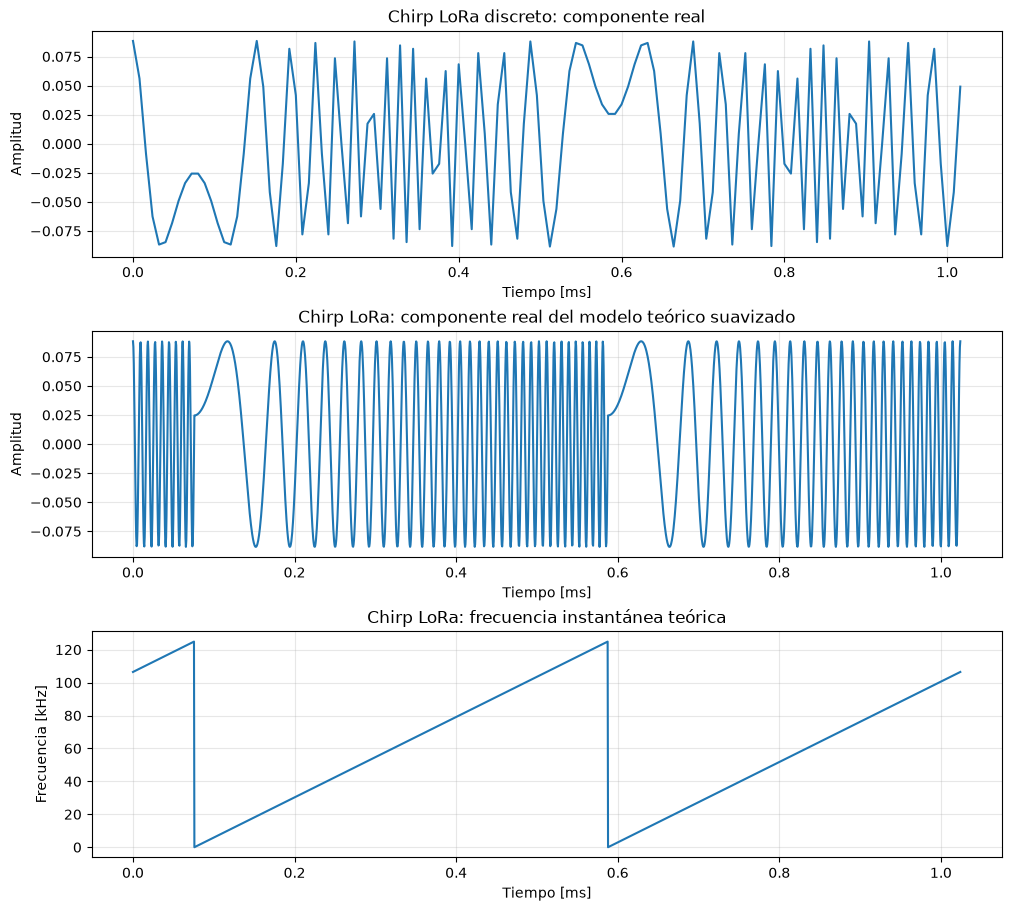

In [26]:
def graficar_curvas(
    tiempo: np.ndarray,
    curvas: list[tuple[str, np.ndarray]],
    *,
    titulo: str,
    etiqueta_y: str,
    ax: Axes | None = None,
) -> Axes:
    """Grafica curvas temporales con el formato común de este notebook."""
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
    for etiqueta, valores in curvas:
        ax.plot(tiempo * 1e3, valores, label=etiqueta)
    ax.set(title=titulo, xlabel='Tiempo [ms]', ylabel=etiqueta_y)
    ax.grid(True, alpha=0.3)
    if len(curvas) > 1:
        ax.legend()
    return ax

def fase_sierra(tiempo: np.ndarray, valor: int) -> np.ndarray:
    # Integra la frecuencia de la sierra para obtener fase continua, en ciclos.
    indice = valor + 2 * B * tiempo
    ciclos_completos = np.floor(indice / N)
    resto = np.mod(indice, N)
    area = (ciclos_completos * N**2 + resto**2) / 2
    return (area - valor**2 / 2) / (2 * N)

def chirp_teorico(tiempo: np.ndarray, valor: int) -> np.ndarray:
    """Extensión continua del chirp discreto; se usa sólo para visualizar."""
    return np.exp(1j * 2 * np.pi * fase_sierra(tiempo, valor)) / np.sqrt(N)

def vista_teorica(valor: int, muestras_por_muestra: int = 16):
    tiempo = np.linspace(0, Ts, N * muestras_por_muestra + 1)
    senal = chirp_teorico(tiempo, valor)
    frecuencia = np.mod(valor + 2 * B * tiempo, N) * B / N
    return tiempo, senal, frecuencia

k = np.arange(N)
tiempo_discreto = k / B
tiempo_suave, chirp_suave, frecuencia_suave = vista_teorica(enviado)

fig, axes = plt.subplots(3, 1, figsize=(10, 9), constrained_layout=True)
graficar_curvas(
    tiempo_discreto, [('Muestras del chirp', chirp.real)],
    titulo='Chirp LoRa discreto: componente real', etiqueta_y='Amplitud', ax=axes[0]
)
graficar_curvas(
    tiempo_suave, [('Modelo teórico', chirp_suave.real)],
    titulo='Chirp LoRa: componente real del modelo teórico suavizado', etiqueta_y='Amplitud', ax=axes[1]
)
graficar_curvas(
    tiempo_suave, [('Frecuencia instantánea', frecuencia_suave / 1e3)],
    titulo='Chirp LoRa: frecuencia instantánea teórica', etiqueta_y='Frecuencia [kHz]', ax=axes[2]
)
plt.show()


## 3. Canal FIR y procesamiento por lotes

**Objetivo.** Introducir el canal selectivo $h[k]=\sqrt{0.8}\delta[k]+\sqrt{0.2}\delta[k-1]$ y preparar la simulación de muchos símbolos. `aplicar_canal_fir` usa `np.convolve`, que es la operación aplicada realmente a la señal discreta. `modular_trama` y `demodular_trama` aplican la misma modulación y detección por filas: no cambian el modelo, sólo evitan un bucle de Python en Monte Carlo. El panel inferior usa la extensión continua equivalente $h[0]c(t)+h[1]c(t-T_m)$ únicamente para visualizar el resultado suavizado del filtro.

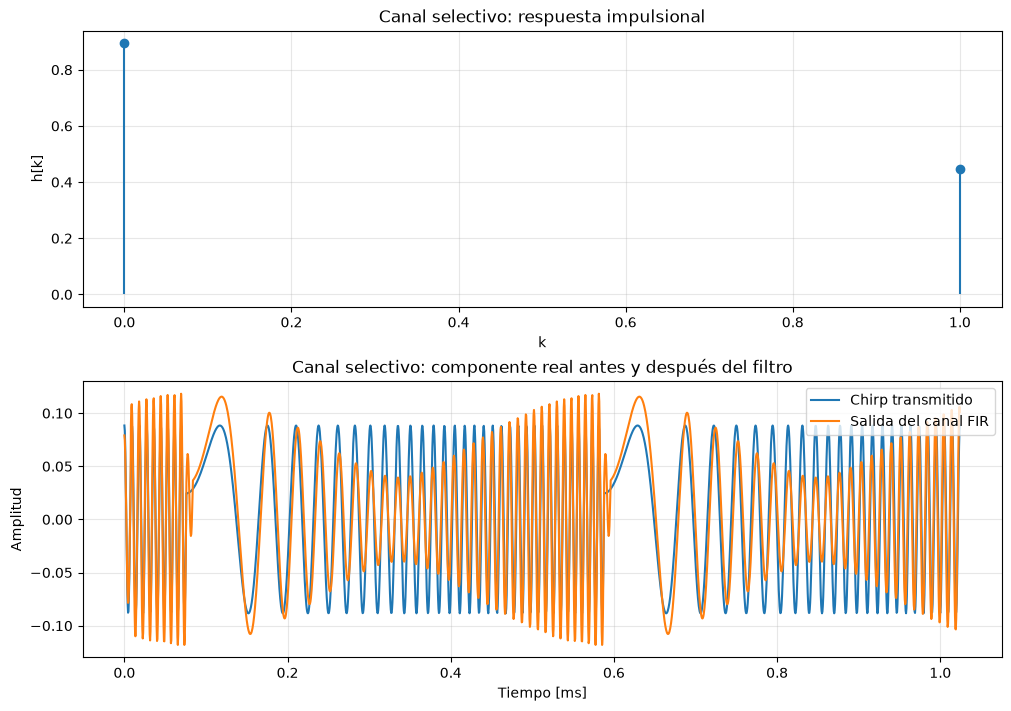

In [27]:
def aplicar_canal_fir(senal: np.ndarray, respuesta_impulsional: np.ndarray) -> np.ndarray:
    # y[k] = sum_m h[m] x[k-m]; np.convolve devuelve también la cola del filtro.
    return np.convolve(senal, respuesta_impulsional)

def modular_trama(valores: np.ndarray) -> np.ndarray:
    # Cada fila corresponde a un símbolo; el broadcasting evalúa todos los chirps juntos.
    k = np.arange(N)
    fase = ((valores[:, None] + k) % N) * k / N
    return np.exp(1j * 2 * np.pi * fase) / np.sqrt(N)

def demodular_trama(recibidas: np.ndarray) -> np.ndarray:
    # El mismo downchirp se multiplica por cada fila y la FFT se calcula sobre axis=1.
    k = np.arange(N)
    downchirp = np.exp(-1j * 2 * np.pi * k**2 / N)
    espectros = np.fft.fft(recibidas * downchirp, axis=1)
    return np.argmax(np.abs(espectros)**2, axis=1)

h = np.array([np.sqrt(0.8), np.sqrt(0.2)])
assert np.isclose(np.sum(np.abs(h)**2), 1.0)
impulso = np.r_[1.0, np.zeros(N - 1)]
np.testing.assert_allclose(aplicar_canal_fir(impulso, h)[:len(h)], h)

# Extensión continua del FIR: h[0] c(t) + h[1] c(t-Tm), con Tm=1/B.
retardo_muestra = 1 / B
chirp_retrasado = chirp_teorico(tiempo_suave - retardo_muestra, enviado)
chirp_retrasado[tiempo_suave < retardo_muestra] = 0
salida_suave = h[0] * chirp_suave + h[1] * chirp_retrasado

fig, axes = plt.subplots(2, 1, figsize=(10, 7), constrained_layout=True)
axes[0].stem(np.arange(len(h)), h, basefmt=' ')
axes[0].set(title='Canal selectivo: respuesta impulsional', xlabel='k', ylabel='h[k]')
axes[0].grid(True, alpha=0.3)
graficar_curvas(
    tiempo_suave,
    [('Chirp transmitido', chirp_suave.real), ('Salida del canal FIR', salida_suave.real)],
    titulo='Canal selectivo: componente real antes y después del filtro',
    etiqueta_y='Amplitud', ax=axes[1]
)
plt.show()


## 4. ¿Dónde se agrega el ruido?

**Objetivo.** Mostrar el orden físico del canal y una realización que produce un error. Primero se calcula $y=c*h$ mediante convolución y luego se suma AWGN: $r=y+w$. Así el ruido es blanco en la entrada del receptor; si se agregara antes, el FIR lo colorearía y sería otro canal. Buscamos una realización con error y graficamos directamente sus muestras reales, sin suavizarlas: el ruido es una realización discreta y conviene verlo como tal.

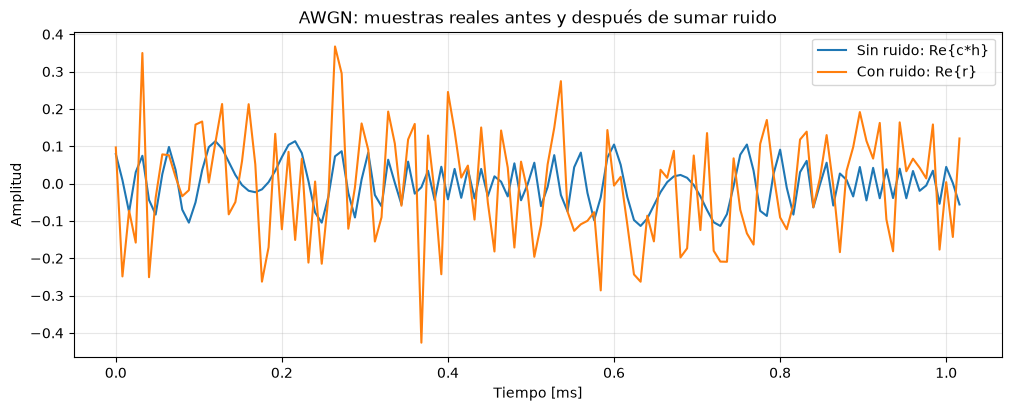

SNR=-7 dB | enviado=1010111 | detectado=1010101


In [ ]:
def transmitir_un_simbolo(valor: int, snr_db: float, generador: np.random.Generator):
    transmitida = modular_simbolo(valor, np.arange(N), N)
    limpia = aplicar_canal_fir(transmitida, h)[:N]
    potencia = float(np.mean(np.abs(transmitida)**2))
    _, sigma = parametros_ruido_desde_snr(snr_db, potencia)
    ruidosa, _ = agregar_ruido_awgn(limpia, sigma, generador)
    detectado, _, _ = demodular_simbolo(ruidosa)
    return limpia, ruidosa, detectado

generador_error = np.random.default_rng(2026)
SNR_ERROR_DB = -7
for _ in range(100): # busco error
    valor_error = int(generador_error.integers(N))
    limpia, ruidosa, detectado_error = transmitir_un_simbolo(
        valor_error, SNR_ERROR_DB, generador_error
    )
    if detectado_error != valor_error: # encontré error, salgo y grafico
        break
else:
    raise RuntimeError('No se encontró un error; probá una SNR menor')

graficar_curvas(
    tiempo_discreto,
    [('Sin ruido: Re{c*h}', limpia.real), ('Con ruido: Re{r}', ruidosa.real)],
    titulo='AWGN: muestras reales antes y después de sumar ruido', etiqueta_y='Amplitud'
)
plt.show()
print(f'SNR={SNR_ERROR_DB} dB | enviado={valor_error:0{SF}b} | detectado={detectado_error:0{SF}b}')


## 5. BER de una trama aleatoria

**Objetivo.** Medir la BER para una SNR concreta antes de barrer varios valores. Se generan 10.000 símbolos equiprobables, se concatenan para aplicar el FIR causal a toda la transmisión y luego se reagrupan para demodular. `calc_error(..., bits_por_simbolo=SF)` compara los 7 bits de cada entero sin convertir miles de símbolos a texto. Finalmente se muestra una fila elegida al azar de esta misma trama: no se crea un experimento adicional.

SNR=-6 dB | BER=1.157e-03 (81 errores sobre 70000 bits)
Potencia señal=0.007812; potencia ruido medida=0.031079; sigma=0.176358


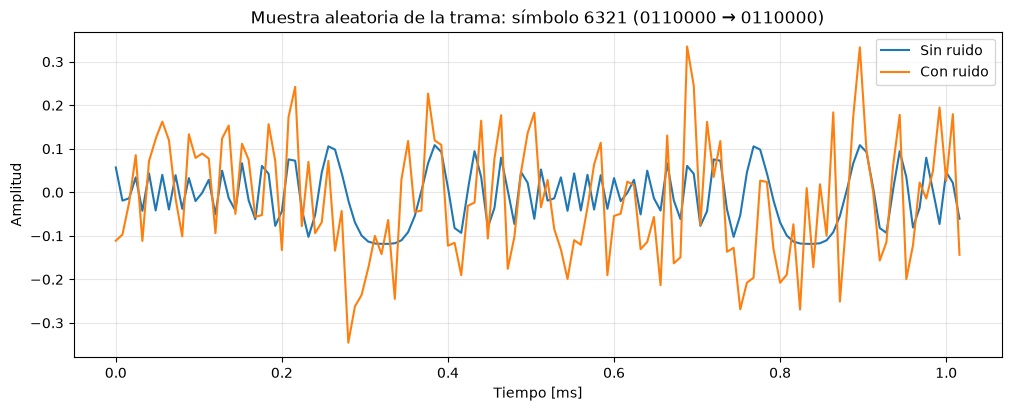

In [29]:
def simular_lote(snr_db: float, cantidad_simbolos: int, generador: np.random.Generator):
    enviados = generador.integers(0, N, cantidad_simbolos)
    transmitida = modular_trama(enviados)
    filtrada = aplicar_canal_fir(transmitida.ravel(), h)[:transmitida.size]
    limpia = filtrada.reshape(cantidad_simbolos, N)

    potencia_senal = float(np.mean(np.abs(transmitida)**2))
    _, sigma = parametros_ruido_desde_snr(snr_db, potencia_senal)
    recibida, ruido = agregar_ruido_awgn(limpia, sigma, generador)
    return enviados, demodular_trama(recibida), limpia, recibida, ruido, potencia_senal, sigma

control = np.arange(N)
control_limpio = aplicar_canal_fir(modular_trama(control).ravel(), h)[:N*N].reshape(N, N)
assert calc_error(control, demodular_trama(control_limpio), bits_por_simbolo=SF) == 0

SNR_EJEMPLO_DB = -6
enviados, estimados, limpia, recibida, ruido, potencia_senal, sigma = simular_lote(
    SNR_EJEMPLO_DB, 10_000, np.random.default_rng(2026)
)
ber_ejemplo = calc_error(enviados, estimados, bits_por_simbolo=SF)
bits_comparados = len(enviados) * SF
errores = round(ber_ejemplo * bits_comparados)
print(f'SNR={SNR_EJEMPLO_DB} dB | BER={ber_ejemplo:.3e} ({errores} errores sobre {bits_comparados} bits)')
print(f'Potencia señal={potencia_senal:.6f}; potencia ruido medida={np.mean(np.abs(ruido)**2):.6f}; sigma={sigma:.6f}')

# Elegimos una fila real de la trama: no es otro experimento ni otro símbolo generado.
indice_muestra = int(np.random.default_rng(2027).integers(len(enviados)))
graficar_curvas(
    tiempo_discreto,
    [('Sin ruido', limpia[indice_muestra].real), ('Con ruido', recibida[indice_muestra].real)],
    titulo=(f'Muestra aleatoria de la trama: símbolo {indice_muestra} '
           f'({enviados[indice_muestra]:0{SF}b} → {estimados[indice_muestra]:0{SF}b})'),
    etiqueta_y='Amplitud'
)
plt.show()


## 6. Curva BER Monte Carlo

**Objetivo.** Estimar la curva BER entre −9 y −3 dB. Para que cada punto tenga una cantidad útil de errores, se simulan lotes de 10.000 símbolos hasta acumular 100 errores de bit o alcanzar 250.000 símbolos. El segundo límite evita que la simulación se vuelva innecesariamente lenta cuando la BER es muy baja; por eso cada fila reporta símbolos, bits y errores junto a su BER.

SNR= -9 dB | símbolos= 10000 | bits=  70000 | errores=1699 | BER=2.427e-02
SNR= -8 dB | símbolos= 10000 | bits=  70000 | errores= 623 | BER=8.900e-03
SNR= -7 dB | símbolos= 10000 | bits=  70000 | errores= 261 | BER=3.729e-03
SNR= -6 dB | símbolos= 10000 | bits=  70000 | errores= 162 | BER=2.314e-03
SNR= -5 dB | símbolos= 30000 | bits= 210000 | errores= 120 | BER=5.714e-04
SNR= -4 dB | símbolos= 80000 | bits= 560000 | errores= 104 | BER=1.857e-04
SNR= -3 dB | símbolos=250000 | bits=1750000 | errores=  90 | BER=5.143e-05


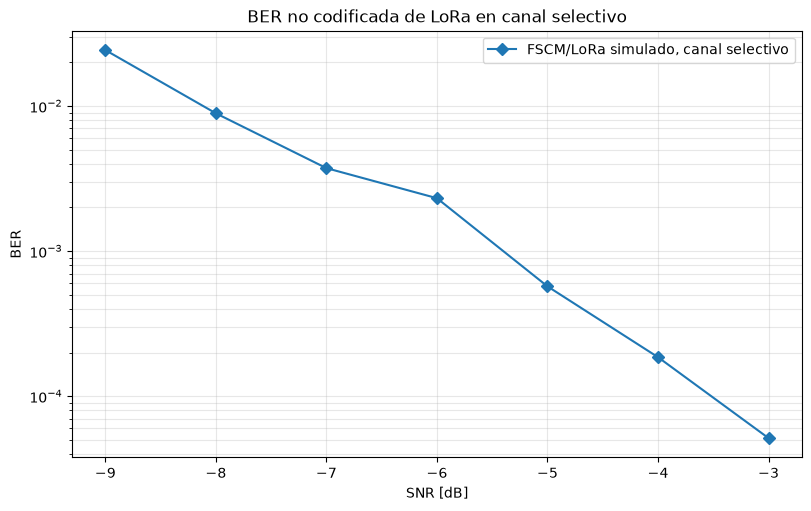

In [30]:
def estimar_ber(snr_db: float, semilla: int) -> tuple[int, int, int, float]:
    generador = np.random.default_rng(semilla)
    errores_totales = bits_totales = simbolos_totales = 0
    while errores_totales < 100 and simbolos_totales < 250_000:
        cantidad = min(10_000, 250_000 - simbolos_totales)
        enviados, estimados, _, _, _, _, _ = simular_lote(snr_db, cantidad, generador)
        ber_lote = calc_error(enviados, estimados, bits_por_simbolo=SF)
        bits_lote = cantidad * SF
        # BER por cantidad de bits recupera el entero de errores de este lote.
        errores_totales += round(ber_lote * bits_lote)
        bits_totales += bits_lote
        simbolos_totales += cantidad
    return simbolos_totales, bits_totales, errores_totales, errores_totales / bits_totales

snr_db = np.arange(-9, -2, 1)
resultados = [estimar_ber(snr, 2026 + indice) for indice, snr in enumerate(snr_db)]
ber = np.array([resultado[-1] for resultado in resultados])
for snr, (simbolos, bits, errores, valor_ber) in zip(snr_db, resultados):
    print(f'SNR={snr:>3} dB | símbolos={simbolos:>6} | bits={bits:>7} | errores={errores:>4} | BER={valor_ber:.3e}')

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.semilogy(snr_db, ber, 'D-', label='FSCM/LoRa simulado, canal selectivo')
ax.set(title='BER no codificada de LoRa en canal selectivo', xlabel='SNR [dB]', ylabel='BER')
ax.set_xticks(snr_db)
ax.grid(True, which='both', alpha=0.3)
ax.legend()
plt.show()


## Conclusión

La simulación discreta sigue siempre la cadena `símbolo → chirp → convolución FIR → AWGN → dechirp/FFT → BER`. La única curva suavizada es el modelo teórico de las secciones 2 y 3; las comparaciones con ruido muestran sus muestras reales para no ocultar su naturaleza aleatoria.